# **Extremal and global-time statistics of sluggish random walks with stochastic resetting.**

## Conventions (identical in all figures, taken from the first paper)
* $r=1$. Everything depends on $\alpha$ and $rT$ only, and lengths scale with $r^{-\mu}$.
* Colour is $\alpha$, with the palette of the first paper: indigo $\alpha=0$ (Brownian motion), orange $\alpha=0.5$, green $\alpha=1.5$;
  markers circle, square, diamond. Panels group the figures by $rT\in\{0.3,3,30\}$ (weak, intermediate, frequent resetting).
  Long-time asymptotics need much larger $rT$ (Figs. 2 and 5).
* Symbols are simulations, solid lines are exact analytic results, dashed lines are asymptotic forms and dotted lines the reset-free limit $r\to0$.
* Where a third parameter appears (the time $T$ in Fig. 3A) red, purple and brown are used. Panels are labelled A, B, C, D.

| Paper | File | Content |
|---|---|---|
| Fig. 1 | `fig01_max_distribution` | density of the maximum and scaling collapse |
| Fig. 2 | `fig02_moments_gumbel` | mean, width and Gumbel law of the maximum |
| Fig. 3 | `fig03_large_deviations` | large deviations and the dynamical transition (two panels; the simulation at T=5 is a recorded check) |
| Fig. 4 | `fig04_tM_distribution` | law of the time of the maximum |
| Fig. 5 | `fig05_boundary_layers` | boundary layers of $t_M$ |
| Fig. 6 | `fig06_mean_offset` | mean offset $\langle t_M\rangle-T/2$ |
| Fig. 7 | `fig07_last_passage` | last-passage time and its Gamma limit |

## How the simulation works
* With $B$ a Brownian motion of diffusivity one, the sluggish walk is $x(t)=B(\tau(t))$ with $dt=|B|^{\alpha}d\tau$.
  We step $B$ with a relative $\Delta\tau$, advance the real-time clock by the trapezoid rule, and use Brownian-bridge sampling inside every step.
* Epochs between resets are i.i.d. A long trajectory is built by resampling complete epochs from a large pool and
  simulating only the last, truncated, epoch afresh. This is exact for the renewal process. Pools come in `R` independent replicates and every
  error bar is the spread between replicates, so the noise of the pool itself is included.

In [1]:
import os, time, math, json, warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.special import ive, gamma, gammainc, erf
from scipy.integrate import quad
from scipy.optimize import brentq
from numpy.polynomial.legendre import leggauss
from numba import njit, prange
import numba
warnings.filterwarnings("ignore", category=RuntimeWarning)

PROFILE = os.environ.get("P2_PROFILE", "paper")
PROFILES = {
    # R blocks (= independent pool replicates for the pool method); every sample size is N = 10^6 in the "paper" profile
    # (N_traj: trajectories per (alpha, rT); N_direct: directly simulated trajectories; N_mfpt: first-passage runs; N_ld: large-deviation check).
    "quick": dict(dtau=4e-3, R=6,  P=3_000,   N_traj=12_000,     N_direct=4_000,     N_mfpt=3_000,     N_ld=100_000,    mp=False, rT_big=1e3),
    "paper": dict(dtau=2e-3, R=10, P=200_000, N_traj=1_000_000,  N_direct=1_000_000, N_mfpt=1_000_000, N_ld=1_000_000,  mp=True,  rT_big=1e4),
}
CFG = PROFILES[PROFILE]
OUT = os.environ.get("P2_OUT", "figs"); os.makedirs(OUT, exist_ok=True)
SEED0 = 20260101
print("profile:", PROFILE, CFG, "| numba threads:", numba.get_num_threads())

mpl.rcParams.update({"font.size": 9, "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "figure.dpi": 110, "savefig.dpi": 300, "lines.linewidth": 1.2, "mathtext.fontset": "dejavusans",
                     "figure.constrained_layout.use": True})

def savefig(fig, name, letters=False):
    """Save a figure as pdf and png. With letters=True the panels are labelled A, B, ... in reading order, as in the first paper,
    for figures whose caption refers to panels by letter."""
    if letters:
        for k, ax in enumerate(fig.axes):
            ax.set_title(f"{chr(65 + k)}", loc="left", fontsize=11, fontweight="bold")
    for ext in ("pdf", "png"): fig.savefig(f"{OUT}/{name}.{ext}", bbox_inches="tight")
    plt.show()
TIMES = {}
class Timer:
    def __init__(self, name): self.name = name
    def __enter__(self): self.t = time.time()
    def __exit__(self, *a): TIMES[self.name] = time.time() - self.t; print(f"[{self.name}] {TIMES[self.name]:.0f} s")

profile: paper {'dtau': 0.002, 'R': 10, 'P': 200000, 'N_traj': 1000000, 'N_direct': 1000000, 'N_mfpt': 1000000, 'N_ld': 1000000, 'mp': True, 'rT_big': 10000.0} | numba threads: 8


## 1. Simulation engine (numba)
The step in $\tau$ is relative: an epoch of duration $e$ uses $\Delta\tau\,e^{2\mu}$, so every epoch has about the same number of steps.
The last zero uses the Brownian-bridge touch probability $\exp(-B B_n/\Delta\tau)$ for steps whose end points have equal sign.

In [2]:

@njit(cache=True)
def epoch_stats(alpha, e, dtau):
    """Free sluggish walk from the origin, run for real time e.
    Time-changed Brownian motion: x(t)=B(tau(t)), B has diffusivity 1, dt=|B|^alpha dtau.
    Returns (max, time of max, last zero, time spent positive)."""
    if e<=0.0:
        return 0.0,0.0,0.0,0.0
    dtau=dtau*e**(2.0/(alpha+2.0))      # relative step: the natural tau-scale of an epoch of duration e is e^(2 mu)
    B=0.0; A=0.0; mx=0.0; tmx=0.0; tl=0.0; tp=0.0
    a = 1.0 if alpha==0.0 else 0.0
    s2=np.sqrt(2.0*dtau)
    while True:
        dB=s2*np.random.randn()
        Bn=B+dB
        an=abs(Bn)**alpha
        dA=0.5*(a+an)*dtau
        if A+dA>=e:
            f=(e-A)/dA
            if f>1.0: f=1.0      # guards against a one-ulp overshoot (sqrt of a negative number)
            if f<0.0: f=0.0
            Bs=B+f*dB+np.sqrt(2.0*f*(1.0-f)*dtau)*np.random.randn()
            h=f*dtau
            u=1.0-np.random.random()
            mb=0.5*(B+Bs+np.sqrt((Bs-B)**2-4.0*h*np.log(u)))
            if mb>mx:
                mx=mb; tmx=A+0.5*(e-A)
            den=abs(B)+abs(Bs)
            if B*Bs<0.0:
                tl=A+(e-A)*abs(B)/den
            elif B*Bs>0.0:
                pt=np.exp(-B*Bs/h)
                if pt>1e-7 and np.random.random()<pt:
                    tl=A+(e-A)*abs(B)/den
            if B>=0.0 and Bs>=0.0: tp+=e-A
            elif B<=0.0 and Bs<=0.0: pass
            elif Bs>0.0: tp+=(e-A)*abs(Bs)/den
            else: tp+=(e-A)*abs(B)/den
            break
        u=1.0-np.random.random()
        mb=0.5*(B+Bn+np.sqrt((Bn-B)**2-4.0*dtau*np.log(u)))
        if mb>mx:
            mx=mb; tmx=A+0.5*dA
        den=abs(B)+abs(Bn)
        if B*Bn<0.0:
            tl=A+dA*abs(B)/den
        elif B*Bn>0.0:
            pt=np.exp(-B*Bn/dtau)
            if pt>1e-7 and np.random.random()<pt:
                tl=A+dA*abs(B)/den
        if B>=0.0 and Bn>=0.0: tp+=dA
        elif B<=0.0 and Bn<=0.0: pass
        elif Bn>0.0: tp+=dA*abs(Bn)/den
        else: tp+=dA*abs(B)/den
        B=Bn; a=an; A+=dA
    return mx,tmx,tl,tp

@njit(cache=True)
def epoch_fpt(alpha, e, dtau, level):
    """Run for real time e or until the level is reached. Returns (hit, time)."""
    dtau=dtau*min(e**(2.0/(alpha+2.0)),level**2)
    B=0.0; A=0.0
    a = 1.0 if alpha==0.0 else 0.0
    s2=np.sqrt(2.0*dtau)
    while True:
        dB=s2*np.random.randn()
        Bn=B+dB
        an=abs(Bn)**alpha
        dA=0.5*(a+an)*dtau
        u=1.0-np.random.random()
        mb=0.5*(B+Bn+np.sqrt((Bn-B)**2-4.0*dtau*np.log(u)))
        if mb>=level:
            tt=A+0.5*dA
            if tt<e: return True,tt
            return False,e
        if A+dA>=e: return False,e
        B=Bn; a=an; A+=dA

@njit(parallel=True, cache=True)
def make_pool(alpha, r, n, dtau, seed):
    pe=np.empty(n); pm=np.empty(n); ptm=np.empty(n); ptl=np.empty(n); ptp=np.empty(n)
    for i in prange(n):
        np.random.seed(seed+i)
        ei=-np.log(1.0-np.random.random())/r
        m,tm,tl,tp=epoch_stats(alpha,ei,dtau)
        pe[i]=ei; pm[i]=m; ptm[i]=tm; ptl[i]=tl; ptp[i]=tp
    return pe,pm,ptm,ptl,ptp

@njit(parallel=True, cache=True)
def trajectories_direct(alpha, r, T, N, dtau, seed):
    M=np.empty(N); tM=np.empty(N); tl=np.empty(N); tp=np.empty(N)
    for i in prange(N):
        np.random.seed(seed+i)
        cum=0.0; gm=0.0; gtm=0.0; gtl=0.0; gtp=0.0
        while True:
            rho=T-cum
            e=-np.log(1.0-np.random.random())/r
            d=min(e,rho)
            m,tm,tl_,tp_=epoch_stats(alpha,d,dtau)
            if m>gm:
                gm=m; gtm=cum+tm
            gtl=cum+tl_; gtp+=tp_
            if e>=rho: break
            cum+=e
        M[i]=gm; tM[i]=gtm; tl[i]=gtl; tp[i]=gtp
    return M,tM,tl,tp

@njit(parallel=True, cache=True)
def trajectories_pool(alpha, r, T, N, dtau, pe, pm, ptm, ptl, ptp, seed):
    """Exact for iid epochs: full epochs are resampled from the pool, the last (truncated)
    epoch is simulated afresh for the remaining time."""
    P=len(pe)
    M=np.empty(N); tM=np.empty(N); tl=np.empty(N); tp=np.empty(N)
    for i in prange(N):
        np.random.seed(seed+i)
        cum=0.0; gm=0.0; gtm=0.0; gtl=0.0; gtp=0.0
        while True:
            rho=T-cum
            j=np.random.randint(0,P)
            if pe[j]<=rho:
                if pm[j]>gm:
                    gm=pm[j]; gtm=cum+ptm[j]
                gtl=cum+ptl[j]; gtp+=ptp[j]; cum+=pe[j]
            else:
                m,tm,tl_,tp_=epoch_stats(alpha,rho,dtau)
                if m>gm:
                    gm=m; gtm=cum+tm
                gtl=cum+tl_; gtp+=tp_
                break
        M[i]=gm; tM[i]=gtm; tl[i]=gtl; tp[i]=gtp
    return M,tM,tl,tp

@njit(parallel=True, cache=True)
def mfpt_direct(alpha, r, level, N, dtau, seed):
    out=np.empty(N)
    for i in prange(N):
        np.random.seed(seed+i)
        tot=0.0
        while True:
            e=-np.log(1.0-np.random.random())/r
            hit,tt=epoch_fpt(alpha,e,dtau,level)
            tot+=tt
            if hit: break
        out[i]=tot
    return out

@njit(parallel=True, cache=True)
def free_stats(alpha, T, N, dtau, seed):
    M=np.empty(N); tM=np.empty(N); tl=np.empty(N); tp=np.empty(N)
    for i in prange(N):
        np.random.seed(seed+i)
        M[i],tM[i],tl[i],tp[i]=epoch_stats(alpha,T,dtau)
    return M,tM,tl,tp

@njit(cache=True)
def record_path(alpha, r, T, dtau, seed, stride, maxpts):
    """One trajectory with resets, recorded every `stride` steps (for illustration only)."""
    np.random.seed(seed)
    ts=np.empty(maxpts); xs=np.empty(maxpts); n=0
    cum=0.0
    while cum<T:
        e=-np.log(1.0-np.random.random())/r
        d=min(e,T-cum)
        B=0.0; A=0.0; a=1.0 if alpha==0.0 else 0.0; k=0
        s2=np.sqrt(2.0*dtau)
        if n<maxpts:
            ts[n]=cum; xs[n]=0.0; n+=1
        while A<d:
            Bn=B+s2*np.random.randn(); an=abs(Bn)**alpha
            A+=0.5*(a+an)*dtau; B=Bn; a=an; k+=1
            if k%stride==0 and n<maxpts and A<d:
                ts[n]=cum+A; xs[n]=B; n+=1
        if n<maxpts:
            ts[n]=cum+d; xs[n]=B; n+=1
        cum+=d
        if cum<T and n<maxpts:
            ts[n]=cum; xs[n]=0.0; n+=1
    return ts[:n],xs[:n]

## 2. Analytic library
Everything below uses only formulas of the paper. Laplace inversions use the fixed-Talbot method in double precision;
Bessel functions are evaluated in exponentially scaled form so that large arguments do not overflow.

In [3]:

def cmu(mu): return 2**mu/gamma(1-mu)
def Amu(mu): return 2**mu*np.sqrt(np.pi/2)/gamma(1-mu)
def Yof(mu,M): return 2*mu*np.asarray(M,float)**(1/(2*mu))
def Mof(mu,Y): return (np.asarray(Y,float)/(2*mu))**(2*mu)

def G_eta(mu,z):
    """G = c_mu/g_mu(z) and eta = g_mu'/g_mu for complex z with Re z>0 (overflow-safe).
    For |z|>2000 the scaled Bessel routine of SciPy is unreliable, and the large-argument expansion of I_nu is used."""
    z=np.asarray(z,complex)
    big=np.abs(z)>2000
    zz=np.where(big,1.0+0j,z)
    S=ive(mu,zz)+ive(-mu,zz); N1=ive(mu-1,zz)+ive(1-mu,zz)
    if np.any(big):
        zb=np.where(big,z,1.0+0j)
        def asy(nu):
            m=4*nu**2; return (1-(m-1)/(8*zb)+(m-1)*(m-9)/(2*(8*zb)**2))/np.sqrt(2*np.pi*zb)
        S=np.where(big,asy(mu)+asy(-mu),S); N1=np.where(big,asy(mu-1)+asy(1-mu),N1)
    G=cmu(mu)*np.exp(-np.abs(z.real))/(z**mu*S)
    eta=N1/S
    return G,eta

# ---------------- fixed-Talbot (Abate-Valko), vectorised over t -----------------
def talbot_nodes(M=16):
    k=np.arange(1,M); th=k*np.pi/M
    delta=np.concatenate(([2*M/5],(2*k*np.pi/5)*(1/np.tan(th)+1j)))
    gam=np.concatenate(([0.5*np.exp(2*M/5)],(1+1j*th*(1+1/np.tan(th)**2)-1j/np.tan(th))*np.exp(delta[1:])))
    return delta,gam

def invert(F,t,M=16):
    """Inverse Laplace transform. F maps an array of complex s (shape (...,)) to an array of the same shape.
    t: array of times. Returns real array shaped like t."""
    t=np.atleast_1d(np.asarray(t,float))
    delta,gam=talbot_nodes(M)
    s=delta[None,:]/t[:,None]
    vals=F(s)
    out=(2/(5*t))*np.sum((gam[None,:]*vals).real,axis=1)
    return out

# ---------------- Gauss-Legendre helper -----------------
def gl_panels(edges,n=40):
    x,w=leggauss(n); X=[];W=[]
    for a,b in zip(edges[:-1],edges[1:]):
        X.append(0.5*(b-a)*x+0.5*(b+a)); W.append(0.5*(b-a)*w)
    return np.concatenate(X),np.concatenate(W)

# ---------------- maximum -----------------
def cdf_M(mu,r,M,T,Mn=16):
    """Prob[M_T<M] (Eq. Qr), vectorised over M for a single T."""
    M=np.atleast_1d(M); Y=Yof(mu,M)
    out=np.empty(len(M))
    for i,y in enumerate(Y):
        def F(s):
            u=s+r; G,_=G_eta(mu,np.sqrt(u)*y)
            return (1-G)/(s+r*G)
        out[i]=invert(F,[T],Mn)[0]
    return out

def pdf_M(mu,r,M,T,Mn=16):
    """Density of M_T from the Laplace transform of dQ/dM."""
    alpha=1/mu-2
    M=np.atleast_1d(M); Y=Yof(mu,M); out=np.empty(len(M))
    for i,(m,y) in enumerate(zip(M,Y)):
        def F(s):
            u=s+r; z=np.sqrt(u)*y; G,eta=G_eta(mu,z)
            return u/(s+r*G)**2*G*eta*np.sqrt(u)*m**(alpha/2)
        out[i]=invert(F,[T],Mn)[0]
    return out

def moments_M(mu,r,T,Mn=16,nM=300):
    """<M_T> and <M_T^2> from Eq. (mean_max) and its analogue, by Laplace inversion."""
    alpha=1/mu-2
    Ymax=60/np.sqrt(r)
    Mmax=Mof(mu,Ymax)
    Mg,wg=gl_panels(np.linspace(0,Mmax,9),nM//8)
    Yg=Yof(mu,Mg)
    def F1(s):
        u=s+r; z=np.sqrt(u)[...,None]*Yg
        G,_=G_eta(mu,z)
        return (u[...,None]*G/(s[...,None]*(s[...,None]+r*G)))@wg
    def F2(s):
        u=s+r; z=np.sqrt(u)[...,None]*Yg
        G,_=G_eta(mu,z)
        return 2*((u[...,None]*G/(s[...,None]*(s[...,None]+r*G)))*Mg)@wg
    return invert(F1,[T],Mn)[0],invert(F2,[T],Mn)[0]

def mfpt(mu,r,M):
    Y=Yof(mu,M)
    z=np.sqrt(r)*Y
    G,_=G_eta(mu,np.array([z+0j]))
    return ((1/G.real-1)/r)[0]

def zeta_star(mu):
    from scipy.optimize import brentq
    from scipy.special import iv
    c=cmu(mu)
    g=lambda z: z**mu*(iv(mu,z)+iv(-mu,z))
    gp=lambda z: z**mu*(iv(mu-1,z)+iv(1-mu,z))
    zs=brentq(lambda z: z*gp(z)-2*(g(z)-c),0.5,6)
    return zs,(g(zs)/c-1)/zs**2

# ---------------- time of the maximum -----------------
def pdf_tM(mu,r,T,xi,nY=70,Mn=16,Ymax=None):
    """Density p(t_M|T) at t_M = xi*T from the time-domain form of Eq. (ptilde):
       p(t_M|T) = int dY F_r(Y,t1) K_r(Y,t2),  t1=t_M, t2=T-t_M."""
    xi=np.atleast_1d(xi); t1=xi*T; t2=(1-xi)*T
    if Ymax is None: Ymax=(np.log(max(r*T,2.0))+22)/np.sqrt(r)
    edgesY=np.concatenate(([0.0],np.geomspace(1e-4,Ymax,26)))   # geometric panels: tiny levels matter when t_M is tiny
    Yg,wg=gl_panels(edgesY,8)
    out=np.zeros(len(xi))
    for y,w in zip(Yg,wg):
        def Ff(s):
            u=s+r; G,_=G_eta(mu,np.sqrt(u)*y)
            return u*G/(s+r*G)
        def Kf(s):
            u=s+r; G,eta=G_eta(mu,np.sqrt(u)*y)
            return np.sqrt(u)*eta/(s+r*G)
        out+=w*invert(Ff,t1,Mn)*invert(Kf,t2,Mn)
    return out

def mean_tM_offset(mu,r,T,Mn=16,Zmax=70):
    """<t_M>-T/2 from Eq. (tM_exact) by Laplace inversion."""
    d=2*(1-mu)
    Zg,wg=gl_panels(np.array([0,0.5,1,2,4,8,16,32,Zmax]),40)
    # G and eta at real Z>0
    G,eta=G_eta(mu,Zg+0j); G=G.real; eta=eta.real
    num=(G*(Zg-d*eta)*wg)
    def F(s):
        return 0.25*np.sum(num[None,None,:]/(s[...,None]+r*G[None,None,:])**2,axis=-1)
    return invert(F,np.atleast_1d(T),Mn)

def aT(mu,r,T):
    A=Amu(mu); L=np.log(A*r*T); return L+(0.5-mu)*np.log(L)

def shift_asym(mu,r,T):
    return (aT(mu,r,T)+np.euler_gamma+mu-1.5)/(4*r)

# ---------------- last passage -----------------
def pdf_tl_u(mu,r,T,u):
    u=np.atleast_1d(u).astype(float)
    t1=r**(1-mu)*u**(-mu)*np.exp(-r*u)/gamma(1-mu)*gammainc(mu,r*(T-u))   # gammainc is regularised
    fl=lambda xi: np.sin(np.pi*mu)/np.pi*xi**(mu-1)*(1-xi)**(-mu)
    return t1+np.exp(-r*T)/T*fl(1-u/T)

# ---------------- occupation time (renewal of Lamperti) -----------------
def var_tplus_rate(mu,r): return (1-mu)/(2*r)

def bin_prob_tM(mu,r,T,a,b,n=16,**kw):
    """Probability that t_M/T lies in [a,b] (exact law). Endpoint singularities of the free law are removed by substitution:
    xi=v^(1/mu) at xi=0 (density ~ xi^(mu-1) at small rT) and 1-xi=v^2 at xi=1 (density ~ (1-xi)^(-1/2))."""
    x,w=leggauss(n)
    if a==0.0:
        va,vb=0.0,b**mu
        v=0.5*(vb-va)*x+0.5*(vb+va); xi=v**(1/mu)
        jac=(1/mu)*v**(1/mu-1)
        return T*0.5*(vb-va)*np.sum(w*pdf_tM(mu,r,T,xi,**kw)*jac)
    if b>0.8:
        va,vb=np.sqrt(1-b),np.sqrt(1-a)
        v=0.5*(vb-va)*x+0.5*(vb+va); xi=1-v**2
        return T*0.5*(vb-va)*np.sum(w*pdf_tM(mu,r,T,xi,**kw)*2*v)
    xi=0.5*(b-a)*x+0.5*(b+a)
    return T*0.5*(b-a)*np.sum(w*pdf_tM(mu,r,T,xi,**kw))

# ---------------- boundary layers of the time of the maximum -----------------

def kappa_right(x):
    """Right boundary layer: T p(t_M|T) -> kappa(r (T-t_M)), kappa(x)=erf(sqrt x)+exp(-x)/sqrt(pi x)."""
    x=np.asarray(x,float); return erf(np.sqrt(x))+np.exp(-x)/np.sqrt(np.pi*x)

def left_edge_profile(mu,r,T,t1,nY=200):
    """Left boundary layer: T p(t_M|T) ~ < P_clim(t1;Y) + p_clim(t1;Y)/r >_Y.
    P_clim is the CDF of the time an epoch needs to reach level Y given that it reaches it before the reset
    (Laplace transform G(M,r+s)/G(M,r)); the average is over the distribution of the level Y of the global maximum."""
    t1=np.atleast_1d(np.asarray(t1,float)); aT_=aT(mu,r,T)
    edges=np.array([max(0.0,aT_-9),aT_-4,aT_-2,aT_,aT_+2,aT_+5,aT_+10,aT_+20])/np.sqrt(r)
    Yg,wg=gl_panels(edges,max(nY//7,8)); out=np.zeros(len(t1))
    for y,w in zip(Yg,wg):
        G0,eta0=G_eta(mu,np.array([np.sqrt(r)*y+0j])); G0=G0.real[0]; eta0=eta0.real[0]
        gam=r*G0; W=T*np.sqrt(r)*eta0*gam*np.exp(-gam*T)*w
        Gh=lambda s: G_eta(mu,np.sqrt(s+r)*y)[0]/G0
        out+=W*(invert(lambda s: Gh(s)/s,t1)+invert(lambda s: Gh(s),t1)/r)
    return out

# ---------------- occupation time -----------------
def var_tplus(mu,r,T):
    """Exact Var(t_+) for all T (from the second p-derivative of Eq. tplus)."""
    T=np.asarray(T,float); return (1-mu)*(r*T-1+np.exp(-r*T))/(2*r**2)

def lamperti_pdf(mu,xi):
    xi=np.asarray(xi,float)
    return np.sin(np.pi*mu)/np.pi*(xi*(1-xi))**(mu-1)/(xi**(2*mu)+2*np.cos(np.pi*mu)*(xi*(1-xi))**mu+(1-xi)**(2*mu))

# ---------------- last passage bins -----------------
def bin_prob_tl(mu,r,T,a,b):
    """Probability that (T-t_l)/T lies in [a,b] (exact law, quad handles the integrable endpoint singularities)."""
    f=lambda xi: pdf_tl_u(mu,r,T,np.array([xi*T]))[0]*T
    return quad(f,a,b,limit=200,epsabs=1e-12,epsrel=1e-10)[0]

# ---------------- free-limit mean of t_M (Del Vecchio & Majumdar, Eq. 41) -----------------
def free_mean_tM(mu):
    f=lambda x: 0.5*x*(G_eta(mu,np.array([x+0j]))[1].real[0]**2)*G_eta(mu,np.array([x+0j]))[0].real[0]
    return quad(f,0,250,limit=400)[0]

# ---------------- moments of M and zeta_max from the pole law exp(-rT G) -----------------
def pole_law_moments(mu,r,T,nM=800):
    Ymax=(np.log(max(r*T,2.0))+40)/np.sqrt(r)
    Mg,wg=gl_panels(np.linspace(0,Mof(mu,Ymax),11),nM//10)
    G,_=G_eta(mu,np.sqrt(r)*Yof(mu,Mg)+0j); F=np.exp(-r*T*G.real)
    m1=np.sum((1-F)*wg); m2=2*np.sum(Mg*(1-F)*wg)
    return m1,m2-m1**2

# ---------------- joint moments of (M, t_M) -----------------
def _FK_derivs(mu,r,s,Y):
    """F~, K and their s-derivatives at fixed Y. s: complex array, Y: array broadcastable against s."""
    u=s+r; Z=np.sqrt(u)*Y; G,eta=G_eta(mu,Z); D=s+r*G
    theta=eta*Z/(2*u); etap=1-(1-2*mu)*eta/Z-eta**2
    F=u*G/D; K=np.sqrt(u)*eta/D
    dF=G*(1-u*theta)/D-u*G*(1-r*G*theta)/D**2
    dK=(eta+Z*etap)/(2*np.sqrt(u)*D)-np.sqrt(u)*eta*(1-r*G*theta)/D**2
    return F,K,dF,dK

def joint_moments(mu,r,T,Mn=16,nY=40,Ymax=None):
    """For one T: offset <t_M>-T/2, cross moment <t_M(T-t_M)>, Var(t_M), and <M t_M>, all by single Laplace inversions."""
    if Ymax is None: Ymax=(np.log(max(r*T,2.0))+25)/np.sqrt(r)
    Yg,wg=gl_panels(np.concatenate(([0.0],np.geomspace(1e-4,Ymax,nY))),6)
    Mg=Mof(mu,Yg)
    def LT(kind):
        def F(s):
            s_=s[...,None]; f,k,df,dk=_FK_derivs(mu,r,s_,Yg[None,None,:])
            if kind=="cross": integrand=df*dk
            elif kind=="m1": integrand=-df*k
            elif kind=="Mm1": integrand=-df*k*Mg[None,None,:]
            return (integrand*wg[None,None,:]).sum(-1)
        return F
    m1=invert(LT("m1"),[T],Mn)[0]; cross=invert(LT("cross"),[T],Mn)[0]; Mm1=invert(LT("Mm1"),[T],Mn)[0]
    off=m1-T/2
    return dict(offset=off,cross=cross,var=T**2/4-cross-off**2,EMt=Mm1)

def cond_mean_tM(mu,r,T,Ylist,Mn=16):
    """<t_M | Y> for a list of levels Y, at observation time T."""
    out=[]
    for y in np.atleast_1d(Ylist):
        def F0(s):
            f,k,df,dk=_FK_derivs(mu,r,s,y); return f*k
        def F1(s):
            f,k,df,dk=_FK_derivs(mu,r,s,y); return -df*k
        out.append(invert(F1,[T],Mn)[0]/invert(F0,[T],Mn)[0])
    return np.array(out)

def cond_mean_tM_bins(mu,r,T,edges,n=6):
    """Exact E[t_M | M in bin] for bins [edges[j],edges[j+1]]: the exact conditional mean averaged with the exact density of M."""
    x,w=leggauss(n); out=[]
    for a,b in zip(edges[:-1],edges[1:]):
        Mn=0.5*(b-a)*x+0.5*(b+a); p=pdf_M(mu,r,Mn,T); c=cond_mean_tM(mu,r,T,Yof(mu,Mn))
        out.append(np.sum(w*p*c)/np.sum(w*p))
    return np.array(out)

## 3. Statistics helpers, pools and the validation registry
Every simulated number is an average over `R` independent blocks. For pool-based samples a block is one pool replicate, so the
quoted error includes the sampling noise of the pool itself. The registry at the end of the notebook collects all comparisons.

In [4]:
CHECKS = []
def record(name, chi2dof, zmax, n, tol_chi=2.5, tol_z=5.0):
    ok = (zmax < tol_z) and (chi2dof < tol_chi)
    CHECKS.append(dict(name=name, chi2dof=float(chi2dof), zmax=float(zmax), n=int(n), status="PASS" if ok else "REVIEW"))
    print(f"   check [{name}]: chi2/dof = {chi2dof:.2f}, max|z| = {zmax:.1f} -> {'PASS' if ok else 'REVIEW'}")

def compare(name, sim, se, th, floor=None, sys_rel=0.0):
    """z-scores of simulation against theory. `sys_rel` adds a known relative discretisation error of the simulation in quadrature."""
    sim, se, th = (np.asarray(v, float) for v in (sim, se, th))
    if floor is not None: se = np.maximum(se, floor)
    se = np.sqrt(se**2 + (sys_rel * th)**2)
    se = np.maximum(se, 1e-14)
    z = (sim - th) / se
    record(name, np.mean(z**2), np.max(np.abs(z)), z.size)
    return z

def blocks_mean(x):
    m = x.mean(axis=1); return m.mean(), m.std(ddof=1) / np.sqrt(len(m))
def blocks_prob(x, edges):
    R = x.shape[0]; P = np.array([np.histogram(x[i], bins=edges)[0] / x.shape[1] for i in range(R)])
    return P.mean(0), P.std(0, ddof=1) / np.sqrt(R)
def blocks_cdf(x, levels):
    R = x.shape[0]; P = np.array([[np.mean(x[i] < l) for l in levels] for i in range(R)])
    return P.mean(0), P.std(0, ddof=1) / np.sqrt(R)

def uniq_seed(*key):
    """Deterministic 30-bit seed base that is different for every (key) so that no two blocks share random numbers."""
    h = 1469598103934665603
    for v in key:
        for ch in repr(v): h = ((h ^ ord(ch)) * 1099511628211) & 0xFFFFFFFFFFFFFFFF
    return int(h % (2**30 - 10_000_000)) + 1

POOLS = {}
CACHE = os.path.join(OUT, "cache"); os.makedirs(CACHE, exist_ok=True)
def get_pools(alpha):
    """R independent pools of P epochs each, cached on disk so that a restart does not repeat the work."""
    if alpha not in POOLS:
        fn = f"{CACHE}/pool_{PROFILE}_a{alpha}_d{CFG['dtau']}_R{CFG['R']}_P{CFG['P']}.npz"
        if os.path.exists(fn):
            z = np.load(fn); POOLS[alpha] = [tuple(z[f"p{k}_{i}"] for i in range(5)) for k in range(CFG["R"])]
        else:
            with Timer(f"pools alpha={alpha}"):
                POOLS[alpha] = [make_pool(alpha, 1.0, CFG["P"], CFG["dtau"], uniq_seed("pool", alpha, k)) for k in range(CFG["R"])]
            np.savez(fn, **{f"p{k}_{i}": POOLS[alpha][k][i] for k in range(CFG["R"]) for i in range(5)})
    return POOLS[alpha]

import pickle
def cached(name, fn):
    """Cache an expensive analytic computation on disk (keyed by profile), so that figures can be restyled without recomputing."""
    fnm = f"{CACHE}/{PROFILE}_{name}.pkl"
    if os.path.exists(fnm): return pickle.load(open(fnm, "rb"))
    val = fn(); pickle.dump(val, open(fnm, "wb")); return val

SAMPLES = {}
def get_samples(alpha, rT, N=None):
    """Trajectories of duration rT (r=1) as arrays of shape (R, n): keys M, tM, tl, tp. Cached on disk for the standard sample size."""
    N = N or CFG["N_traj"]; key = (alpha, float(rT), N); fnm = f"{CACHE}/samples_{PROFILE}_a{alpha}_rT{float(rT):g}_N{N}.npz"
    if key not in SAMPLES:
        if N == CFG["N_traj"] and os.path.exists(fnm):
            z = np.load(fnm); SAMPLES[key] = {nm: z[nm] for nm in ("M", "tM", "tl", "tp")}
        else:
            pools = get_pools(alpha); R = len(pools); n = N // R
            out = [trajectories_pool(alpha, 1.0, float(rT), n, CFG["dtau"], *pools[k], uniq_seed("traj", alpha, float(rT), N, k))
                   for k in range(R)]
            SAMPLES[key] = {nm: np.stack([o[i] for o in out]) for i, nm in enumerate(["M", "tM", "tl", "tp"])}
            if N == CFG["N_traj"]: np.savez(fnm, **SAMPLES[key])
    return SAMPLES[key]

def get_direct(alpha, r, T, N=None, tag=0):
    N = N or CFG["N_direct"]; R = CFG["R"]; n = N // R
    out = [trajectories_direct(alpha, r, float(T), n, CFG["dtau"], uniq_seed("direct", alpha, r, float(T), tag, k)) for k in range(R)]
    return {nm: np.stack([o[i] for o in out]) for i, nm in enumerate(["M", "tM", "tl", "tp"])}

## Figure conventions in code
One place defines the look of all figures, as in the first paper: **colour = $\alpha$** (blue 0, orange 0.5, green 1.5), simulations are
symbols and exact results solid lines, dashed lines are asymptotic forms and dotted lines the reset-free limit. Panels are grouped by $rT$.

In [7]:
from matplotlib.lines import Line2D
mpl.rcParams.update({"font.size": 12, "axes.labelsize": 12, "legend.fontsize": 10, "xtick.labelsize": 11, "ytick.labelsize": 11, "axes.titlesize": 12,
                     "legend.frameon": True, "legend.framealpha": 0.85, "legend.edgecolor": "none"})
ALPHAS = (0.0, 0.5, 1.5); RTS = (0.3, 3.0, 30.0)
COL = {0.0: "#3F51B5", 0.5: "#FF9800", 1.5: "#2E7D32"}     # indigo, orange, green: the palette of the first paper
MKA = {0.0: "o", 0.5: "s", 1.5: "D"}                          # circle, square, diamond, as in the first paper
TCOL = ("#D32F2F", "#7B1FA2", "#795548")                      # red, purple, brown, for a third parameter (T in Fig. 3)
RMK = ("v", "P", "X")                                         # markers for the rate r in the collapse panel
RTTITLE = {0.3: r"Weak resetting, $rT=0.3$", 3.0: r"Intermediate, $rT=3$", 30.0: r"Frequent resetting, $rT=30$"}
def alpha_handles(extra=()):
    return [Line2D([], [], color=COL[a], marker=MKA[a], ms=4, lw=1.2, label=f"α={a:g}") for a in ALPHAS] + list(extra)
def sym(ax, x, y, e, color, mk, ms=3.4):
    ax.errorbar(x, y, e, fmt=mk, ms=(ms - 0.6 if mk == "D" else ms), mfc=color, mec=color, mew=0, color=color, alpha=0.9, elinewidth=0.7, capsize=0, lw=0)
FREE = Line2D([], [], color="0.5", ls=":", lw=1.3, label=r"$r\to0$")

def Cmu(mu):
    """Prefactor of the free mean, <M_T> = C_mu T^mu."""
    g = lambda z: G_eta(mu, np.array([z + 0j]))[0].real[0]
    return (2 * mu)**(1 - 2 * mu) / gamma(1 + mu) * quad(lambda z: z**(2 * mu - 1) * g(z), 0, 200, limit=400)[0]

@njit(parallel=True, cache=True)
def _bm_exact_nb(rT, n, seed):
    """Exact (M, t_M, t_l) for alpha=0 (Brownian motion, D=1, r=1): n trajectories of duration rT, no pool and no time step.
    The reset times form a Poisson process (exponential gaps). In an epoch of duration g the time of the maximum is theta = g sin^2(pi U/2)
    (arcsine law), and given theta the maximum is sqrt(-4 theta ln V) (density proportional to m exp(-m^2/(4 theta))). The global maximum is the largest epoch
    maximum and t_M is its epoch start plus theta. The last zero of the final (truncated) epoch is its start plus g sin^2(pi U'/2)."""
    M = np.empty(n); tM = np.empty(n); tl = np.empty(n)
    for i in prange(n):
        np.random.seed(seed + i)
        cum = 0.0; best = -1.0; tbest = 0.0; tlast = 0.0
        while True:
            g = -np.log(1.0 - np.random.random()); last = False
            if cum + g >= rT:
                g = rT - cum; last = True
            th = g * np.sin(0.5 * np.pi * np.random.random())**2
            m = np.sqrt(-4.0 * th * np.log(1.0 - np.random.random()))
            if m > best:
                best = m; tbest = cum + th
            if last:
                tlast = cum + g * np.sin(0.5 * np.pi * np.random.random())**2
                break
            cum += g
        M[i] = best; tM[i] = tbest; tl[i] = tlast
    return M, tM, tl

def bm_exact_times(rT, N=None, R=None):
    """Exact (M, t_M, t_l) for alpha=0 as arrays of shape (R, N/R), cached on disk. The numba sampler makes N = 10^6 feasible up to rT = 10^4."""
    N = N or CFG["N_traj"]; R = R or CFG["R"]; n = N // R; fnm = f"{CACHE}/bmtimes_{PROFILE}_rT{float(rT):g}_N{N}.npz"
    if os.path.exists(fnm): z = np.load(fnm); return {k: z[k] for k in ("M", "tM", "tl")}
    out = {k: np.empty((R, n)) for k in ("M", "tM", "tl")}
    for k in range(R):
        m, tm, tl = _bm_exact_nb(float(rT), n, uniq_seed("bmexact", float(rT), N, k)); out["M"][k] = m; out["tM"][k] = tm; out["tl"][k] = tl
    np.savez(fnm, **out); return out
def bm_exact_M(rT, N=None, R=None):
    """Exact maxima for alpha=0, shape (R, N/R). Needed for the moments at large rT: the maximum over ~rT epochs reaches into the exponential tail
    of the epoch-maximum law, which a finite pool of epochs cannot represent."""
    return bm_exact_times(rT, N, R)["M"]
def traj(alpha, rT):
    """Samples of (M, t_M, t_l): exact sampler for alpha=0, pool simulation otherwise."""
    return bm_exact_times(rT) if alpha == 0 else get_samples(alpha, rT)

def maxima(alpha, rT):
    """Samples of M_T: exact sampler for alpha=0, pool simulation otherwise."""
    return bm_exact_M(rT) if alpha == 0 else get_samples(alpha, rT)["M"]

## Figure 1. Distribution of the maximum and scaling collapse
(A-C) Density $p_r(M,T)$ for $rT=0.3,3,30$, one colour per $\alpha$: exact inversion of Eq. (Qr) (lines) against histograms (symbols).
(D) Collapse of $\mathrm{Prob}[M_T<M]$ at $rT=3$ against $r^{\mu}M$ for three rates $r$.

In [ ]:
with Timer("Fig1 maximum distribution"):
    fig, axs = plt.subplots(2, 2, figsize=(7.0, 5.4)); Ntot = CFG["N_traj"]; rTc = 3.0
    for ax, rT in zip(axs.flat[:3], RTS):
        xmax = max(np.quantile(get_samples(a, rT)["M"], 0.995) for a in ALPHAS); w = xmax / 34
        for alpha in ALPHAS:
            mu = 1 / (alpha + 2); M_ = get_samples(alpha, rT)["M"]; edges = np.arange(0, np.quantile(M_, 0.995) + w, w)
            p, se = blocks_prob(M_, edges); mid = 0.5 * (edges[1:] + edges[:-1]); Mg = np.linspace(1e-3, edges[-1], 200)
            ax.plot(Mg, pdf_M(mu, 1.0, Mg, rT), color=COL[alpha]); sym(ax, mid, p / w, se / w, COL[alpha], MKA[alpha])
            pth = np.diff(np.concatenate(([0.0], cdf_M(mu, 1.0, edges[1:], rT))))
            compare(f"Fig1 p(M) alpha={alpha} rT={rT}", p, se, pth, floor=0.5 * np.sqrt(np.maximum(pth, 1e-9) / Ntot))
        ax.set_title(RTTITLE[rT]); ax.set_xlabel(r"$M$"); ax.set_ylabel(r"$p_r(M,T)$"); ax.legend(handles=alpha_handles())
    ax = axs.flat[3]; lv = np.linspace(0.4, 3.6, 7)
    for alpha in ALPHAS:
        mu = 1 / (alpha + 2); Mg = np.linspace(0.02, 5.0, 150); ax.plot(Mg, cdf_M(mu, 1.0, Mg, rTc), color=COL[alpha])
        for r, mk in zip((0.25, 1.0, 4.0), RMK):
            D = get_direct(alpha, r, rTc / r, tag=int(r * 100)); c, e = blocks_cdf(D["M"] * r**mu, lv); sym(ax, lv, c, e, COL[alpha], mk, ms=3.8)
            compare(f"Fig1 collapse alpha={alpha} r={r}", c, e, cdf_M(mu, 1.0, lv, rTc), floor=0.5 * np.sqrt(0.25 / CFG["N_direct"]))
    rh = [Line2D([], [], color="0.4", marker=mk, ms=4, ls="", label=rf"$r={r:g}$") for r, mk in zip((0.25, 1.0, 4.0), RMK)]
    ax.legend(handles=[Line2D([], [], color=COL[a], lw=1.2, label=f"α={a:g}") for a in ALPHAS] + rh, loc="lower right"); ax.set_xlabel(r"$r^{\mu}M$"); ax.set_ylabel(r"$\mathrm{Prob}[M_T<M]$"); ax.set_title(rf"Collapse at $rT={rTc:g}$")
    savefig(fig, "fig01_max_distribution", letters=True)

[pools alpha=1.5] 67 s
   check [Fig1 p(M) alpha=0.0 rT=0.3]: chi2/dof = 1.65, max|z| = 3.8 -> PASS
   check [Fig1 p(M) alpha=0.5 rT=0.3]: chi2/dof = 0.90, max|z| = 2.5 -> PASS
   check [Fig1 p(M) alpha=1.5 rT=0.3]: chi2/dof = 1.14, max|z| = 2.3 -> PASS
   check [Fig1 p(M) alpha=0.0 rT=3.0]: chi2/dof = 0.78, max|z| = 2.3 -> PASS
   check [Fig1 p(M) alpha=0.5 rT=3.0]: chi2/dof = 2.03, max|z| = 3.8 -> PASS
   check [Fig1 p(M) alpha=1.5 rT=3.0]: chi2/dof = 1.37, max|z| = 2.0 -> PASS
   check [Fig1 p(M) alpha=0.0 rT=30.0]: chi2/dof = 1.37, max|z| = 2.4 -> PASS
   check [Fig1 p(M) alpha=0.5 rT=30.0]: chi2/dof = 1.72, max|z| = 3.9 -> PASS
   check [Fig1 p(M) alpha=1.5 rT=30.0]: chi2/dof = 0.69, max|z| = 1.8 -> PASS
   check [Fig1 collapse alpha=0.0 r=0.25]: chi2/dof = 1.04, max|z| = 1.6 -> PASS
   check [Fig1 collapse alpha=0.0 r=1.0]: chi2/dof = 0.86, max|z| = 1.3 -> PASS
   check [Fig1 collapse alpha=0.0 r=4.0]: chi2/dof = 0.98, max|z| = 1.5 -> PASS
   check [Fig1 collapse alpha=0.5 r=4.0]

## Figure 2. Moments of the maximum and the Gumbel law
(A) $\langle M_T\rangle$ and (b) $\sqrt{\mathrm{Var}\,M_T}$ against $rT$: exact (solid), free law $C_\mu T^{\mu}$ (dotted), large-$rT$ law and Gumbel width (dashed).
(C) Distribution function of $\zeta_{\max}-a_T$ at $rT=10^3$ against the Gumbel law.
For $\alpha=0$ the maxima are sampled exactly (`bm_exact_M`, numba, $N=10^6$ at every $rT$), because the pool of epochs cannot represent the exponential tail that sets the moments at large $rT$.

   check [Fig2 mean M alpha=0.0]: chi2/dof = 1.17, max|z| = 2.6 -> PASS
   check [Fig2 std M alpha=0.0]: chi2/dof = 1.33, max|z| = 2.0 -> PASS
   check [Fig2 CDF vs exact law alpha=0.0 rT=1000]: chi2/dof = 1.01, max|z| = 2.7 -> PASS
      alpha=0.0 rT=100: max |exact - Gumbel| on xi in [-1,2] = 0.0082
      alpha=0.0 rT=10000: max |exact - Gumbel| on xi in [-1,2] = 0.0001
   check [Fig2 mean M alpha=0.5]: chi2/dof = 1.45, max|z| = 2.5 -> PASS
   check [Fig2 std M alpha=0.5]: chi2/dof = 0.95, max|z| = 1.6 -> PASS
   check [Fig2 CDF vs exact law alpha=0.5 rT=1000]: chi2/dof = 0.60, max|z| = 2.0 -> PASS
      alpha=0.5 rT=100: max |exact - Gumbel| on xi in [-1,2] = 0.0016
      alpha=0.5 rT=10000: max |exact - Gumbel| on xi in [-1,2] = 0.0027
   check [Fig2 mean M alpha=1.5]: chi2/dof = 1.97, max|z| = 2.8 -> PASS
   check [Fig2 std M alpha=1.5]: chi2/dof = 0.94, max|z| = 1.3 -> PASS
   check [Fig2 CDF vs exact law alpha=1.5 rT=1000]: chi2/dof = 0.94, max|z| = 2.3 -> PASS
      alpha=1.5 r

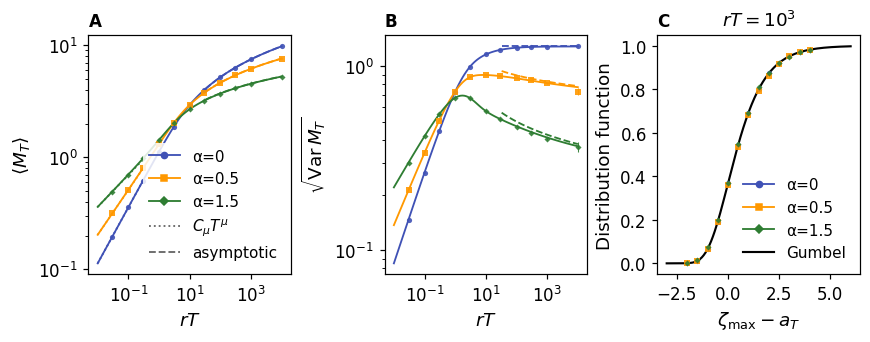

[Fig2 moments and Gumbel] 1101 s


In [9]:
with Timer("Fig2 moments and Gumbel"):
    rTl = [0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000, CFG["rT_big"]]; Tg = np.logspace(-2, np.log10(CFG["rT_big"]), 100); lev = np.linspace(-2, 4, 13); rTg = 1e3
    fig, axs = plt.subplots(1, 3, figsize=(7.8, 3.0))
    for alpha in ALPHAS:
        mu = 1 / (alpha + 2); th = np.array(cached(f"moments_a{alpha}", lambda: [moments_M(mu, 1.0, T) for T in Tg])); m1, sd = th[:, 0], np.sqrt(th[:, 1] - th[:, 0]**2)
        axs[0].plot(Tg, m1, color=COL[alpha]); axs[1].plot(Tg, sd, color=COL[alpha])
        tl_ = Tg[Tg < 0.3]; axs[0].plot(tl_, Cmu(mu) * tl_**mu, color=COL[alpha], ls=":", lw=1.2)
        tt = Tg[Tg > 30]; axs[0].plot(tt, Mof(mu, aT(mu, 1.0, tt) + np.euler_gamma), color=COL[alpha], ls="--", lw=1.2)
        axs[1].plot(tt, np.pi / np.sqrt(6) * 2 * mu * Mof(mu, aT(mu, 1.0, tt)) / aT(mu, 1.0, tt), color=COL[alpha], ls="--", lw=1.2)
        m_s, e_s, m_t, s_s, es_s, s_t = [], [], [], [], [], []
        for rT in rTl:
            M_ = maxima(alpha, rT); a, ea = blocks_mean(M_); sb = M_.std(axis=1, ddof=1); tm1, tm2 = moments_M(mu, 1.0, rT)
            m_s.append(a); e_s.append(ea); m_t.append(tm1); s_s.append(sb.mean()); es_s.append(sb.std(ddof=1) / np.sqrt(len(sb))); s_t.append(np.sqrt(tm2 - tm1**2))
        sym(axs[0], rTl, m_s, e_s, COL[alpha], MKA[alpha]); sym(axs[1], rTl, s_s, es_s, COL[alpha], MKA[alpha])
        compare(f"Fig2 mean M alpha={alpha}", m_s, e_s, m_t); compare(f"Fig2 std M alpha={alpha}", s_s, es_s, s_t)
        a = aT(mu, 1.0, rTg); c, e = blocks_cdf(Yof(mu, maxima(alpha, rTg)) - a, lev); exact = cdf_M(mu, 1.0, Mof(mu, a + lev), rTg)
        sym(axs[2], lev, c, e, COL[alpha], MKA[alpha]); compare(f"Fig2 CDF vs exact law alpha={alpha} rT={rTg:g}", c, e, exact, floor=0.5 * np.sqrt(0.2 / CFG["N_traj"]))
        for rT_ in (1e2, 1e4):
            ex_ = cdf_M(mu, 1.0, Mof(mu, aT(mu, 1.0, rT_) + np.linspace(-1, 2, 25)), rT_); print(f"      alpha={alpha} rT={rT_:g}: max |exact - Gumbel| on xi in [-1,2] = {np.max(np.abs(ex_ - np.exp(-np.exp(-np.linspace(-1, 2, 25))))):.4f}")
    xi = np.linspace(-3, 6, 200); axs[2].plot(xi, np.exp(-np.exp(-xi)), color="k", lw=1.4)
    for ax, yl in zip(axs[:2], (r"$\langle M_T\rangle$", r"$\sqrt{\mathrm{Var}\,M_T}$")): ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"$rT$"); ax.set_ylabel(yl)
    axs[0].legend(handles=alpha_handles([Line2D([], [], color="0.4", ls=":", label=r"$C_\mu T^{\mu}$"), Line2D([], [], color="0.4", ls="--", label="asymptotic")]), loc="lower right")
    axs[2].set_xlabel(r"$\zeta_{\max}-a_T$"); axs[2].set_ylabel("Distribution function"); axs[2].set_title(rf"$rT=10^{{{int(np.log10(rTg))}}}$")
    axs[2].legend(handles=alpha_handles([Line2D([], [], color="k", lw=1.4, label="Gumbel")]), loc="lower right")
    savefig(fig, "fig02_moments_gumbel", letters=True)

## Figure 3. Large deviations and the dynamical transition
(A) Approach of the exact rate to $\Phi(w)$ with growing $T$ ($\alpha=1.5$), (b) independence of $\alpha$ at the largest $T$, (c) ratio of simulated to exact probability at $T=5$.
The three $T$ values use red, purple and brown, since colour means $\alpha$ elsewhere.

   check [Fig3 LD sim vs exact alpha=0.0]: chi2/dof = 0.80, max|z| = 1.6 -> PASS
   check [Fig3 LD sim vs exact alpha=0.5]: chi2/dof = 2.49, max|z| = 4.0 -> PASS
   check [Fig3 LD sim vs exact alpha=1.5]: chi2/dof = 1.56, max|z| = 2.2 -> PASS


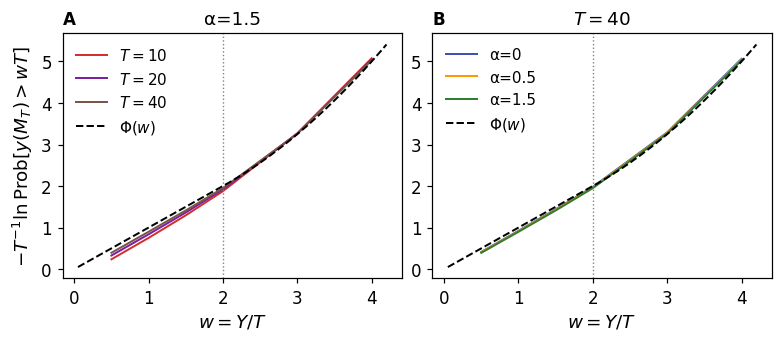

[Fig3 large deviations] 246 s


In [10]:
import mpmath as mp
def tail_exact_mp(mu, T, w, r=1.0):
    """Prob[y(M_T) > w T] from the exact transform, in extended precision."""
    Phi = np.sqrt(r) * w if w < 2 * np.sqrt(r) else w**2 / 4 + r
    mp.mp.dps = int(T * Phi / 2.3) + 40; mu_ = mp.mpf(mu); c_ = 2**mu_ / mp.gamma(1 - mu_); Y = w * T
    g_ = lambda z: z**mu_ * (mp.besseli(mu_, z) + mp.besseli(-mu_, z))
    F = lambda s: (r + s) * (c_ / g_(mp.sqrt(r + s) * Y)) / (s + r * c_ / g_(mp.sqrt(r + s) * Y)) / s
    return mp.invertlaplace(F, T, method="talbot")
Phi_th = lambda w, r=1.0: np.where(w < 2 * np.sqrt(r), np.sqrt(r) * w, w**2 / 4 + r)

with Timer("Fig3 large deviations"):
    fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.0)); wg = np.linspace(0.05, 4.2, 200)
    ws = (0.5, 1.0, 1.5, 2.0, 3.0, 4.0) if CFG["mp"] else (1.0, 3.0); Ts = (10, 20, 40) if CFG["mp"] else (5, 10); Tmax = Ts[-1]
    def ldcurve(alpha, T):
        mu = 1 / (alpha + 2); return cached(f"ld_a{alpha}_T{T}", lambda: [(w, -float(mp.log(tail_exact_mp(mu, T, w))) / T) for w in ws])
    for T, c in zip(Ts, TCOL): axs[0].plot(*zip(*ldcurve(1.5, T)), color=c, lw=1.3, label=rf"$T={T}$")
    for alpha in ALPHAS: axs[1].plot(*zip(*ldcurve(alpha, Tmax)), color=COL[alpha], lw=1.3, label=f"α={alpha:g}")
    for ax in axs[:2]:
        ax.plot(wg, Phi_th(wg), color="k", ls="--", lw=1.3, label=r"$\Phi(w)$"); ax.axvline(2.0, color="gray", ls=":", lw=0.9)
        ax.set_xlabel(r"$w=Y/T$"); ax.legend(loc="upper left")
    axs[0].set_ylabel(r"$-T^{-1}\ln\mathrm{Prob}[y(M_T)>wT]$"); axs[0].set_title("α=1.5"); axs[1].set_title(rf"$T={Tmax}$")
    T = 5.0; wv = np.linspace(0.5, 2.6, 12)
    def ldsim(alpha):
        mu = 1 / (alpha + 2); Mx = bm_exact_M(T, N=CFG["N_ld"]) if alpha == 0 else get_samples(alpha, T, N=CFG["N_ld"])["M"]; Ntot = Mx.size; y = Yof(mu, Mx); out = []
        for w in wv:
            ex = float(tail_exact_mp(mu, T, w)); pb = (y > w * T).mean(axis=1)
            if ex * Ntot < 30: continue
            m = pb.mean(); e = pb.std(ddof=1) / np.sqrt(len(pb)); out.append((w, m / ex, e / ex, (m - ex) / max(e, 1e-12)))
        return out
    for k, alpha in enumerate(ALPHAS):
        res = cached(f"ldsim_a{alpha}", lambda: ldsim(alpha)); zl = [r_[3] for r_ in res]
        record(f"Fig3 LD sim vs exact alpha={alpha}", np.mean(np.square(zl)), np.max(np.abs(zl)), len(zl))   # compared with the exact probabilities at T=5, not plotted
    savefig(fig, "fig03_large_deviations", letters=True)

## Figure 4. Distribution of the time of the maximum
$T\,p(t_M|T)$ against $t_M/T$ for $rT=0.3,3,30$ (panels) and $\alpha=0,0.5,1.5$ (colours): exact law (lines), histograms (symbols), reset-free law (dotted, same colour).
20 bins of width 0.05 (25 time steps of the $\alpha=0$ clock each, so the bins do not alias with the time lattice).
**All bins are drawn.** In the two outermost bins the density diverges, so the bin average of the density differs from its value at the bin centre. The exact bin average
(from the integrated theory, the same quantity that enters the z-scores) is drawn there as a short horizontal bar of the colour of $\alpha$.

   check [Fig4 p(tM|T) alpha=0.0 rT=0.3]: chi2/dof = 2.38, max|z| = 3.4 -> PASS
      alpha=0.0 rT=0.3: sum of exact bin probabilities 1.00000; end-bin averages (theory, simulation): left 2.358, 2.352; right 2.873, 2.867
   check [Fig4 p(tM|T) alpha=0.5 rT=0.3]: chi2/dof = 1.35, max|z| = 2.7 -> PASS
      alpha=0.5 rT=0.3: sum of exact bin probabilities 1.00000; end-bin averages (theory, simulation): left 3.193, 3.202; right 2.958, 2.954
   check [Fig4 p(tM|T) alpha=1.5 rT=0.3]: chi2/dof = 0.99, max|z| = 3.0 -> PASS
      alpha=1.5 rT=0.3: sum of exact bin probabilities 1.00000; end-bin averages (theory, simulation): left 4.355, 4.357; right 3.016, 3.014
   check [Fig4 p(tM|T) alpha=0.0 rT=3]: chi2/dof = 2.19, max|z| = 3.0 -> PASS
      alpha=0.0 rT=3: sum of exact bin probabilities 1.00000; end-bin averages (theory, simulation): left 0.593, 0.584; right 2.480, 2.489
   check [Fig4 p(tM|T) alpha=0.5 rT=3]: chi2/dof = 1.07, max|z| = 2.8 -> PASS
      alpha=0.5 rT=3: sum of exact bin pro

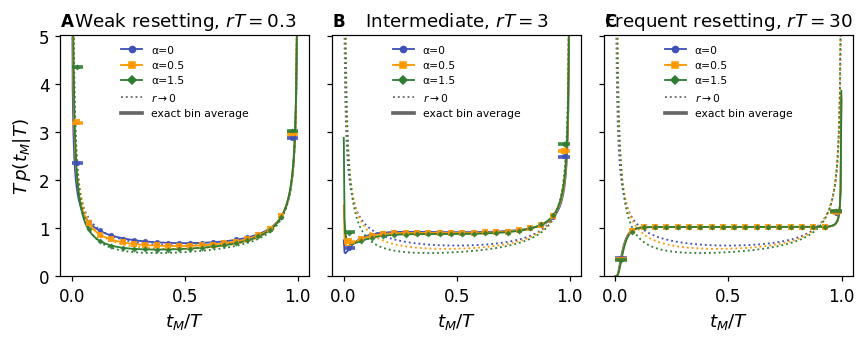

[Fig4 time of the maximum] 454 s


In [11]:
with Timer("Fig4 time of the maximum"):
    nb = 20; edges = np.linspace(0, 1, nb + 1); mid = 0.5 * (edges[1:] + edges[:-1]); xg = np.linspace(0.0008, 0.9992, 300)
    fig, axs = plt.subplots(1, 3, figsize=(7.8, 3.0), sharey=True); ymax = 3.2
    for ax, rT in zip(axs, RTS):
        for alpha in ALPHAS:
            mu = 1 / (alpha + 2)
            free = 1 / (np.pi * np.sqrt(xg * (1 - xg))) if alpha == 0 else cached(f"tMfree_a{alpha}", lambda: pdf_tM(mu, 1.0, 1e-3, xg) * 1e-3)
            ax.plot(xg, free, color=COL[alpha], ls=":", lw=1.2)
            S = traj(alpha, rT); p, se = blocks_prob(S["tM"] / rT, edges)
            pth = np.array([bin_prob_tM(mu, 1.0, rT, edges[k], edges[k + 1], n=16) for k in range(nb)])
            ax.plot(xg, cached(f"tMd_a{alpha}_rT{rT:g}_nb{nb}", lambda: pdf_tM(mu, 1.0, rT, xg) * rT), color=COL[alpha])
            sym(ax, mid, p * nb, se * nb, COL[alpha], MKA[alpha])
            for k in (0, nb - 1): ax.hlines(pth[k] * nb, edges[k], edges[k + 1], color=COL[alpha], lw=2.4, alpha=0.9, zorder=4); ymax = max(ymax, 1.15 * pth[k] * nb)
            compare(f"Fig4 p(tM|T) alpha={alpha} rT={rT:g}", p, se, pth, floor=0.5 * np.sqrt(np.maximum(pth, 1e-9) / CFG["N_traj"]))
            print(f"      alpha={alpha} rT={rT:g}: sum of exact bin probabilities {pth.sum():.5f}; end-bin averages (theory, simulation): left {pth[0]*nb:.3f}, {p[0]*nb:.3f}; right {pth[-1]*nb:.3f}, {p[-1]*nb:.3f}")
        ax.set_xlabel(r"$t_M/T$"); ax.set_title(RTTITLE[rT]); ax.legend(handles=alpha_handles([Line2D([], [], color="0.4", ls=":", label=r"$r\to0$"), Line2D([], [], color="0.4", lw=2.4, label="exact bin average")]), loc="upper center", fontsize=7)
    axs[0].set_ylim(0, ymax); axs[0].set_ylabel(r"$T\,p(t_M|T)$"); savefig(fig, "fig04_tM_distribution", letters=True)

## Figure 5. Boundary layers of $t_M$ at long times ($rT=10^3$)
(A) Left layer against $t_M$ (units $1/r$): exact (solid), climbing-time form (dashed), simulation (symbols).
(B) Right layer against $\rho=r(T-t_M)$: exact (solid), $\kappa(\rho)$ (dashed), simulation (symbols).

The layers are rare events, since only about 0.1% of the trajectories have $t_M$ within one unit of $1/r$ of an end of the window. With $N=10^6$ trajectories the symbols are
therefore binned averages: the bins are wide (panel A) or unequal (panel B, narrow where $\kappa$ diverges as $\rho^{-1/2}$ and wide elsewhere), so that each bin holds enough trajectories.
Symbols are bin averages of the density. In panel B they are drawn at $\rho^*=\big((\sqrt a+\sqrt b)/2\big)^2$ for the bin $[a,b]$, the point where the density equals its bin average
for a $\rho^{-1/2}$ singularity, so that the symbols lie on the curve (for wide bins $\rho^*$ is the midpoint).
The z-scores are computed against exact bin probabilities, not against the curve at the bin centre.

In [12]:
# ---- Dedicated t_M samples for Fig. 5 -----------------------------------------------------------------------------------------------
# N = 10^6 trajectories at rT = 10^3, as in every other figure. Only t_M is stored. For alpha = 0 the exact sampler is used.
N_LAYER = CFG["N_traj"]

@njit(parallel=True, cache=True)
def bm_exact_tM_fast(rT, n, seed):
    """Exact t_M for alpha=0 (Brownian motion, D=1, r=1): Poisson reset times built from exponential gaps (no sorting), epoch maximum
    from the arcsine time theta = g sin^2(pi U/2) and m = sqrt(-4 theta ln V). Same law as bm_exact_times, but n trajectories in seconds."""
    out = np.empty(n)
    for i in prange(n):
        np.random.seed(seed + i)
        cum = 0.0; best = -1.0; tbest = 0.0
        while True:
            g = -np.log(1.0 - np.random.random()); last = False
            if cum + g >= rT:
                g = rT - cum; last = True
            th = g * np.sin(0.5 * np.pi * np.random.random())**2
            m = np.sqrt(-4.0 * th * np.log(1.0 - np.random.random()))
            if m > best:
                best = m; tbest = cum + th
            if last: break
            cum += g
        out[i] = tbest
    return out

def layer_tM(alpha, rT, N=None):
    """t_M samples of shape (R, N/R) for Fig. 5, cached on disk. alpha=0: exact sampler. alpha>0: pool method with the standard pools."""
    N = N or N_LAYER; R = CFG["R"]; n = N // R
    fnm = f"{CACHE}/layer_tM_{PROFILE}_a{alpha}_rT{float(rT):g}_N{N}.npy"
    if os.path.exists(fnm): return np.load(fnm)
    if alpha == 0:
        out = np.stack([bm_exact_tM_fast(float(rT), n, uniq_seed("layerbm", float(rT), N, k)) for k in range(R)])
    else:
        pools = get_pools(alpha)
        out = np.stack([trajectories_pool(alpha, 1.0, float(rT), n, CFG["dtau"], *pools[k], uniq_seed("layertraj", alpha, float(rT), N, k))[1]
                        for k in range(R)])
    np.save(fnm, out); return out

   check [Fig5 left layer alpha=0.0]: chi2/dof = 0.78, max|z| = 1.6 -> PASS
   check [Fig5 right layer alpha=0.0]: chi2/dof = 1.04, max|z| = 1.6 -> PASS
      alpha=0.0: N=1000000, largest error bar of T p: left 0.037, right 0.075; block spread / Poisson spread (right, median): 0.98
      alpha=0.0: exact vs asymptotic layers, max |difference| left = 0.0023, right = 0.0022
   check [Fig5 left layer alpha=0.5]: chi2/dof = 0.57, max|z| = 1.2 -> PASS
   check [Fig5 right layer alpha=0.5]: chi2/dof = 1.84, max|z| = 2.2 -> PASS
      alpha=0.5: N=1000000, largest error bar of T p: left 0.025, right 0.101; block spread / Poisson spread (right, median): 1.02
      alpha=0.5: exact vs asymptotic layers, max |difference| left = 0.0024, right = 0.0428
   check [Fig5 left layer alpha=1.5]: chi2/dof = 1.16, max|z| = 2.5 -> PASS
   check [Fig5 right layer alpha=1.5]: chi2/dof = 1.25, max|z| = 2.5 -> PASS
      alpha=1.5: N=1000000, largest error bar of T p: left 0.036, right 0.125; block spread / P

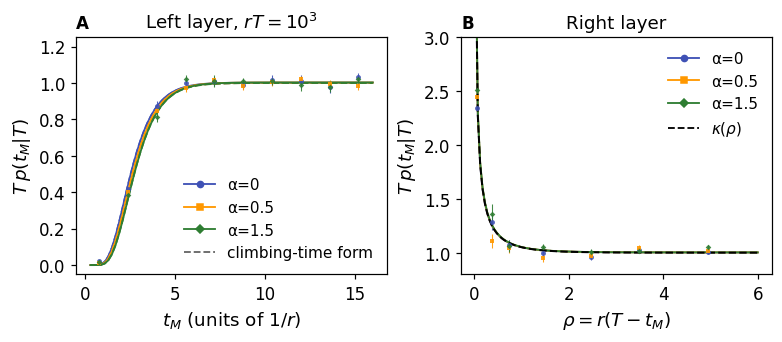

[Fig5 boundary layers] 252 s


In [13]:
with Timer("Fig5 boundary layers"):
    rT = 1e3 if CFG["rT_big"] >= 1e3 else CFG["rT_big"]; fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.0))
    eL = np.linspace(0, 16, 11)                                  # left layer: 10 bins of width 1.6 (units of 1/r)
    eR = np.array([0, 0.25, 0.5, 1, 2, 3, 4, 6.0])               # right layer: narrow bins where kappa diverges, wide ones elsewhere
    # Symbols are bin averages of the density. For the integrable divergence rho^(-1/2) the bin average equals the density at
    # rho* = ((sqrt a + sqrt b)/2)^2, so the right-layer symbols are drawn there, which puts them on the curve (rho* = midpoint for wide bins).
    midL = 0.5 * (eL[1:] + eL[:-1]); midR = (0.5 * (np.sqrt(eR[1:]) + np.sqrt(eR[:-1])))**2
    tg = np.linspace(0.3, 16, 80); rg = np.linspace(0.02, 6, 120)
    for alpha in ALPHAS:
        mu = 1 / (alpha + 2); tM = layer_tM(alpha, rT)
        # left layer, panel A
        exL = cached(f"layL_a{alpha}", lambda: pdf_tM(mu, 1.0, rT, tg / rT) * rT); apL = cached(f"layLa_a{alpha}", lambda: left_edge_profile(mu, 1.0, rT, tg))
        axs[0].plot(tg, exL, color=COL[alpha]); axs[0].plot(tg, apL, color=COL[alpha], ls="--", lw=1.2)
        pL, sL = blocks_prob(tM, eL); pthL = np.array([bin_prob_tM(mu, 1.0, rT, eL[k] / rT, eL[k + 1] / rT, n=24) for k in range(len(eL) - 1)])
        sym(axs[0], midL, pL / np.diff(eL) * rT, sL / np.diff(eL) * rT, COL[alpha], MKA[alpha], ms=3.2)
        compare(f"Fig5 left layer alpha={alpha}", pL, sL, pthL, floor=0.5 * np.sqrt(np.maximum(pthL, 1e-9) / N_LAYER))
        # right layer, panel B, in the variable rho = r (T - t_M)
        exR = cached(f"layR_rho_a{alpha}", lambda: pdf_tM(mu, 1.0, rT, 1 - rg / rT) * rT); axs[1].plot(rg, exR, color=COL[alpha])
        pR, sR = blocks_prob(rT - tM, eR); pthR = np.array([bin_prob_tM(mu, 1.0, rT, 1 - eR[k + 1] / rT, 1 - eR[k] / rT, n=24) for k in range(len(eR) - 1)])
        sym(axs[1], midR, pR / np.diff(eR) * rT, sR / np.diff(eR) * rT, COL[alpha], MKA[alpha], ms=3.2)
        compare(f"Fig5 right layer alpha={alpha}", pR, sR, pthR, floor=0.5 * np.sqrt(np.maximum(pthR, 1e-9) / N_LAYER))
        # statistical error bars (in the units of the plot) and block spread relative to the pure counting (Poisson) spread, about 1 if pool noise is negligible
        errL = sL / np.diff(eL) * rT; errR = sR / np.diff(eR) * rT; poiR = np.sqrt(np.maximum(pR, 1e-300) / N_LAYER)
        print(f"      alpha={alpha}: N={N_LAYER}, largest error bar of T p: left {errL.max():.3f}, right {errR.max():.3f}; block spread / Poisson spread (right, median): {np.median(sR / poiR):.2f}")
        print(f"      alpha={alpha}: exact vs asymptotic layers, max |difference| left = {np.max(np.abs(exL - apL)):.4f}, right = {np.max(np.abs(exR - kappa_right(rg))):.4f}")
    axs[1].plot(rg, kappa_right(rg), color="k", ls="--", lw=1.3); axs[1].set_ylim(0.8, 3.0); axs[0].set_ylim(-0.05, 1.25)
    axs[0].set_xlabel(r"$t_M$ (units of $1/r$)"); axs[0].set_ylabel(r"$T\,p(t_M|T)$"); axs[0].set_title(rf"Left layer, $rT=10^{{{int(np.log10(rT))}}}$")
    axs[0].legend(handles=alpha_handles([Line2D([], [], color="0.4", ls="--", label="climbing-time form")]), loc="lower right")
    axs[1].set_xlabel(r"$\rho=r(T-t_M)$"); axs[1].set_ylabel(r"$T\,p(t_M|T)$"); axs[1].set_title("Right layer")
    axs[1].legend(handles=alpha_handles([Line2D([], [], color="k", ls="--", label=r"$\kappa(\rho)$")]), loc="upper right")
    savefig(fig, "fig05_boundary_layers", letters=True)

## Figure 6. Mean offset $\langle t_M\rangle-T/2$
(A) $r(\langle t_M\rangle-T/2)$ against $rT$: exact (solid; closed form for $\alpha=0$), asymptotic law (dashed), simulation (symbols).
(B) The offset divided by $T$ at small $rT$ with the reset-free values (dotted).

      alpha=0 closed form vs inversion, max abs diff: 2.014477473721854e-11
   check [Fig6 offset alpha=0.0]: chi2/dof = 1.29, max|z| = 2.0 -> PASS
   check [Fig6 offset alpha=0.5]: chi2/dof = 1.75, max|z| = 2.3 -> PASS
   check [Fig6 offset alpha=1.5]: chi2/dof = 3.07, max|z| = 3.7 -> REVIEW


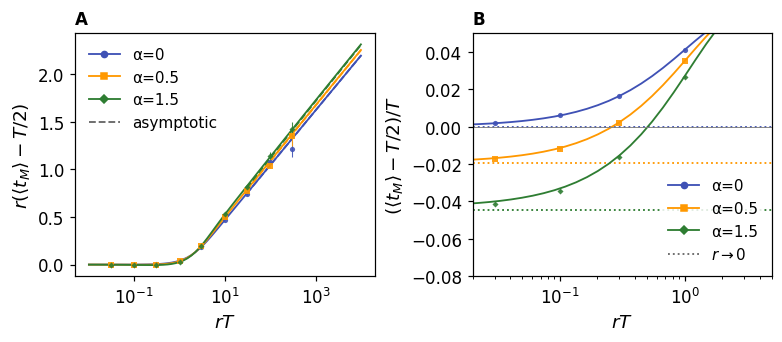

[Fig6 mean offset] 8 s


In [14]:
from scipy.special import exp1
with Timer("Fig6 mean offset"):
    fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.0)); Tg = np.logspace(-2, np.log10(CFG["rT_big"]), 70)
    rTs = [0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300]   # rT=1000 is not simulated: the finite pool lacks the longest epochs and biases the offset low
    for alpha in ALPHAS:
        mu = 1 / (alpha + 2); off = np.array(cached(f"offset_a{alpha}", lambda: mean_tM_offset(mu, 1.0, Tg)))
        if alpha == 0: cf = (exp1(Tg) + np.log(Tg) + np.euler_gamma - 1 + np.exp(-Tg)) / 4; print("      alpha=0 closed form vs inversion, max abs diff:", np.max(np.abs(cf - off))); off = cf
        axs[0].plot(Tg, off, color=COL[alpha]); axs[1].plot(Tg, off / Tg, color=COL[alpha])
        tt = Tg[Tg > 30]; axs[0].plot(tt, shift_asym(mu, 1.0, tt), color=COL[alpha], ls="--", lw=1.2)
        m_, e_, t_ = [], [], []
        for rT in rTs:
            S = traj(alpha, rT); a, ea = blocks_mean(S["tM"] - rT / 2); m_.append(a); e_.append(ea); t_.append(mean_tM_offset(mu, 1.0, rT)[0])
        m_, e_, t_, rr = map(np.array, (m_, e_, t_, rTs)); sym(axs[0], rr, m_, e_, COL[alpha], MKA[alpha]); compare(f"Fig6 offset alpha={alpha}", m_, e_, t_)
        sym(axs[1], rr[rr <= 3], (m_ / rr)[rr <= 3], (e_ / rr)[rr <= 3], COL[alpha], MKA[alpha])
        axs[1].axhline(free_mean_tM(mu) - 0.5, color=COL[alpha], ls=":", lw=1.2)
    axs[0].set_xscale("log"); axs[0].set_xlabel(r"$rT$"); axs[0].set_ylabel(r"$r(\langle t_M\rangle-T/2)$")
    axs[0].legend(handles=alpha_handles([Line2D([], [], color="0.4", ls="--", label="asymptotic")]), loc="upper left")
    axs[1].set_xscale("log"); axs[1].set_xlim(0.02, 5); axs[1].set_ylim(-0.08, 0.05); axs[1].axhline(0, color="gray", lw=0.6)
    axs[1].set_xlabel(r"$rT$"); axs[1].set_ylabel(r"$(\langle t_M\rangle-T/2)/T$"); axs[1].legend(handles=alpha_handles([Line2D([], [], color="0.4", ls=":", label=r"$r\to0$")]), loc="lower right")
    savefig(fig, "fig06_mean_offset", letters=True)

## Figure 7. Last-passage time
$u\,p(u|T)$, the density of $u=T-t_l$ per logarithmic interval, against $ru$ for $rT=0.3,3,30$ (panels) and $\alpha=0,0.5,1.5$ (colours): Eq. (tl_exact) (solid), Gamma limit Eq. (tl_gamma) (dashed), histograms (symbols) from $u=0.01$ on, above the time-step scale of the simulation.
**All bins are drawn.** In the last bin, which ends at $u=T$ where the density diverges, the exact bin average is drawn as a short horizontal bar. The cell also checks the exact mean $\langle T-t_l\rangle=(1-\mu)(1-e^{-rT})/r$.

   check [Fig7 p(u|T) alpha=0.0 rT=0.3]: chi2/dof = 1.31, max|z| = 2.1 -> PASS
   check [Fig7 p(u|T) alpha=0.5 rT=0.3]: chi2/dof = 0.87, max|z| = 1.9 -> PASS
   check [Fig7 p(u|T) alpha=1.5 rT=0.3]: chi2/dof = 0.74, max|z| = 1.5 -> PASS
   check [Fig7 p(u|T) alpha=0.0 rT=3]: chi2/dof = 1.80, max|z| = 2.8 -> PASS
   check [Fig7 p(u|T) alpha=0.5 rT=3]: chi2/dof = 0.70, max|z| = 1.6 -> PASS
   check [Fig7 p(u|T) alpha=1.5 rT=3]: chi2/dof = 1.73, max|z| = 2.7 -> PASS
   check [Fig7 p(u|T) alpha=0.0 rT=30]: chi2/dof = 0.72, max|z| = 1.8 -> PASS
   check [Fig7 p(u|T) alpha=0.5 rT=30]: chi2/dof = 1.38, max|z| = 2.8 -> PASS
   check [Fig7 p(u|T) alpha=1.5 rT=30]: chi2/dof = 0.69, max|z| = 2.1 -> PASS


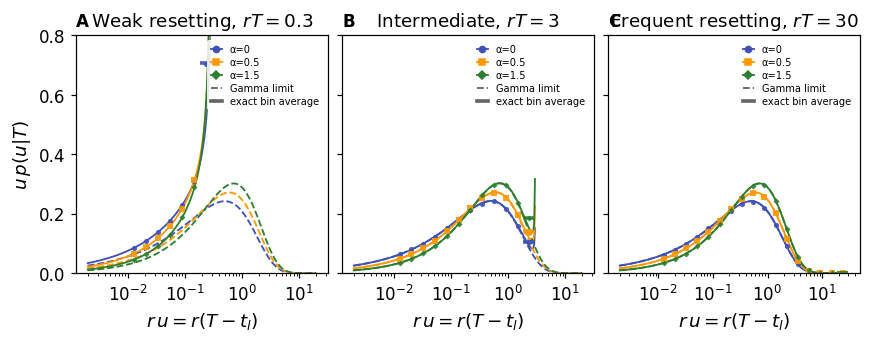

   check [Fig7 mean of T-tl alpha=0.0]: chi2/dof = 2.99, max|z| = 2.9 -> REVIEW
      alpha=0.0: <T-t_l> simulation [0.12955 0.47529 0.50107], exact [0.12959 0.47511 0.5    ]
   check [Fig7 mean of T-tl alpha=0.5]: chi2/dof = 3.14, max|z| = 2.1 -> REVIEW
      alpha=0.5: <T-t_l> simulation [0.15542 0.56918 0.59857], exact [0.15551 0.57013 0.6    ]
   check [Fig7 mean of T-tl alpha=1.5]: chi2/dof = 1.59, max|z| = 1.7 -> PASS
      alpha=1.5: <T-t_l> simulation [0.18515 0.67766 0.71279], exact [0.18513 0.67872 0.71429]
[Fig7 last passage] 10 s


In [15]:
with Timer("Fig7 last passage"):
    fig, axs = plt.subplots(1, 3, figsize=(7.8, 3.0), sharey=True); ug = np.geomspace(2e-3, 20, 300)
    for ax, rT in zip(axs, RTS):
        for alpha in ALPHAS:
            mu = 1 / (alpha + 2); ax.plot(ug, ug**(1 - mu) * np.exp(-ug) / gamma(1 - mu), color=COL[alpha], ls="--", lw=1.2)
            u = rT - traj(alpha, rT)["tl"]; nbins = max(6, int(np.log(rT / 1e-2) / 0.5) + 1); edges = np.geomspace(1e-2, rT, nbins + 1); p, se = blocks_prob(u, edges); dln = np.diff(np.log(edges)); ctr = np.sqrt(edges[1:] * edges[:-1])
            pth = np.array([bin_prob_tl(mu, 1.0, rT, edges[k] / rT, edges[k + 1] / rT) for k in range(len(edges) - 1)]); ur = ug[ug < 0.999 * rT]
            ax.plot(ur, ur * pdf_tl_u(mu, 1.0, rT, ur), color=COL[alpha]); sym(ax, ctr, p / dln, se / dln, COL[alpha], MKA[alpha])
            ax.hlines(pth[-1] / dln[-1], edges[-2], edges[-1], color=COL[alpha], lw=2.4, alpha=0.9, zorder=4)
            compare(f"Fig7 p(u|T) alpha={alpha} rT={rT:g}", p, se, pth, floor=0.5 * np.sqrt(np.maximum(pth, 1e-9) / CFG["N_traj"]))
        ax.set_xscale("log"); ax.set_ylim(0, 0.8); ax.set_xlabel(r"$r\,u=r(T-t_l)$"); ax.set_title(RTTITLE[rT])
        ax.legend(handles=alpha_handles([Line2D([], [], color="0.4", ls="--", label="Gamma limit"), Line2D([], [], color="0.4", lw=2.4, label="exact bin average")]), loc="upper right", fontsize=6.5, handlelength=1.1, labelspacing=0.3)
    axs[0].set_ylabel(r"$u\,p(u|T)$"); savefig(fig, "fig07_last_passage", letters=True)
    # exact mean of u = T - t_l, <u> = (1 - mu)(1 - exp(-rT))/r, against the simulation (a check of the result quoted in the paper)
    for alpha in ALPHAS:
        mu = 1 / (alpha + 2); m_, e_, t_ = [], [], []
        for rT in (0.3, 3.0, 30.0):
            a_, ea_ = blocks_mean(rT - traj(alpha, rT)["tl"]); m_.append(a_); e_.append(ea_); t_.append((1 - mu) * (1 - np.exp(-rT)))
        compare(f"Fig7 mean of T-tl alpha={alpha}", m_, e_, t_); print(f"      alpha={alpha}: <T-t_l> simulation {np.round(m_, 5)}, exact {np.round(t_, 5)}")